### 实验3 卷积神经网络计算机视觉基础 (CIFAR-10)

#### 一、基本实现过程
##### 1.1 基本设置
（1）导入torch等第三方库

In [16]:
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F # 函数式接口模块
from torch.utils.data import DataLoader, TensorDataset # 数据集组织，以便后面batch划分
import torch.optim as optim # 优化器

（2）设置图表显示

In [17]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker  # 导入刻度格式化模块
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC']  # 支持中文字体
plt.rcParams['figure.dpi'] = 300   # Notebook 中显示的清晰度
plt.rcParams['savefig.dpi'] = 300  # 保存图片的清晰度
plt.rcParams['font.size'] = 12

（3）观察设备情况，以便后面使用GPU

In [18]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"正在使用的设备: {device}")

正在使用的设备: cuda


（4）设置固定随机种子，以便复现

In [19]:
# 设置随机种子（不含对batch划分的设置）
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)                # PyTorch CPU随机数
    torch.cuda.manual_seed(seed)           # PyTorch 当前GPU随机数
    torch.cuda.manual_seed_all(seed)       # PyTorch 所有GPU随机数
    torch.backends.cudnn.deterministic = True # 强制CuDNN使用确定性算法
    torch.backends.cudnn.benchmark = False # 关闭CuDNN的自动寻找最优算法

set_seed(42)

##### 1.2 数据导入与预处理
（1）导入数据集并观察形状

In [20]:
import tarfile

tar_path = './data/cifar-10-batches-py.tar.gz'

with tarfile.open(tar_path, 'r:gz') as tar:
    tar.extractall('./data')

In [21]:
from torchvision import datasets, transforms

# 图片预处理
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])

# 加载训练集
train_dataset = datasets.CIFAR10(
    root='./data',
    train=True,
    transform=transform,
    download=False
)

# 加载测试集
test_dataset = datasets.CIFAR10(
    root='./data',
    train=False,
    transform=transform,
    download=False
)

# 创建 DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

In [22]:
print(train_dataset.data.shape)
print(test_dataset.data.shape)

(50000, 32, 32, 3)
(10000, 32, 32, 3)


In [23]:
train_dataset.data

array([[[[ 59,  62,  63],
         [ 43,  46,  45],
         [ 50,  48,  43],
         ...,
         [158, 132, 108],
         [152, 125, 102],
         [148, 124, 103]],

        [[ 16,  20,  20],
         [  0,   0,   0],
         [ 18,   8,   0],
         ...,
         [123,  88,  55],
         [119,  83,  50],
         [122,  87,  57]],

        [[ 25,  24,  21],
         [ 16,   7,   0],
         [ 49,  27,   8],
         ...,
         [118,  84,  50],
         [120,  84,  50],
         [109,  73,  42]],

        ...,

        [[208, 170,  96],
         [201, 153,  34],
         [198, 161,  26],
         ...,
         [160, 133,  70],
         [ 56,  31,   7],
         [ 53,  34,  20]],

        [[180, 139,  96],
         [173, 123,  42],
         [186, 144,  30],
         ...,
         [184, 148,  94],
         [ 97,  62,  34],
         [ 83,  53,  34]],

        [[177, 144, 116],
         [168, 129,  94],
         [179, 142,  87],
         ...,
         [216, 184, 140],
        

In [ ]:
# 自定义CNN结构
class CNN(nn.Module):

    def __init__(self):
        super(CNN, self).__init__()

        # 第一层卷积：3个输入通道，32个输出通道
        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        # 第二层卷积：32个输入通道，64个输出通道
        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        # 最大池化：尺寸缩小一半
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # 全连接层
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        # 第一组卷积 + 激活 + 池化
        x = self.conv1(x)
        x = F.relu(x)
        x = self.pool(x)

        # 第二组卷积 + 激活 + 池化
        x = self.conv2(x)
        x = F.relu(x)
        x = self.pool(x)

        # 展平
        x = torch.flatten(x, start_dim=1)

        # 全连接分类
        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x


（2）创建model对象，设置loss函数与优化器

In [ ]:
model = CNN() # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

（3）训练模型，并评估每epoch的结果

In [ ]:
# 训练模型，并在每轮epoch后，针对训练数据评估模型
def train_model(model, epochs, batch):
    # 将模型迁移到GPU训练
    model = model.to(device)

    # 全数据集分batch
    g = torch.Generator()
    g.manual_seed(42) # 为了可复现，为batch划分也设置固定随机种子
    
    loss_result = []

    for epoch in range(epochs):
        train_total_loss_sum = 0.0  # 记录每个epoch的总损失
        train_num = 0   # 记录训练集的总样本数

        model.train() # 设置为训练模式
        for batch_x, batch_y in train_loader:
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad() # 梯度清零
            preds_y = model(batch_x) # 前向传播
            loss_train = criterion(preds_y, batch_y) # 计算损失
            loss_train.backward() # 反向传播（自动求导 并 累加梯度）
            optimizer.step() # 根据求导计算出的 梯度，更新模型参数

            train_total_loss_sum += loss_train.item() * batch_y.size(0) # 为便于最后计算总平均loss，通过乘以batch样本数，加和单batch下的loss总和
            train_num += batch_y.size(0)

        train_correct = 0
        
        model.eval() # 设置为评估模式
        with torch.no_grad(): # 关闭梯度计算，节省内存
            for batch_x, batch_y in train_loader:
                batch_x = batch_x.to(device)
                batch_y = batch_y.to(device)

                train_preds = model(batch_x) # 前向传播                
                predicted_classes = torch.argmax(train_preds, dim=1) # 将概率最大的标签值，作为预测结果
                train_correct += (predicted_classes == batch_y).sum().item() # 统计预测正确的样本数
        
        loss_result.append([f"{epoch + 1}/{epochs}", train_total_loss_sum / train_num, train_correct / train_num]) # 记录每epoch的loss与Acc
        # print(f"训练进度: {epoch+1}/{epochs}, 训练集loss: {train_total_loss_sum / train_num:.4f}, 训练集Acc: {train_correct / train_num * 100:.2f}%  ({train_correct}/{train_num})")

    result_df = pd.DataFrame(loss_result, columns=['Epoch', 'Loss', 'Acc'])
    return result_df

In [ ]:
train_result_df = train_model(model, epochs=15, batch = 128)
train_result_df.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.238923,97.76%
2/15,0.062329,98.20%
3/15,0.044215,99.02%
4/15,0.033392,99.36%
5/15,0.025354,99.50%
6/15,0.020299,99.46%
7/15,0.015812,99.73%
8/15,0.012695,99.80%
9/15,0.010278,99.77%
10/15,0.008227,99.80%


（4）绘制Baseline的loss与Acc曲线，查看收敛情况

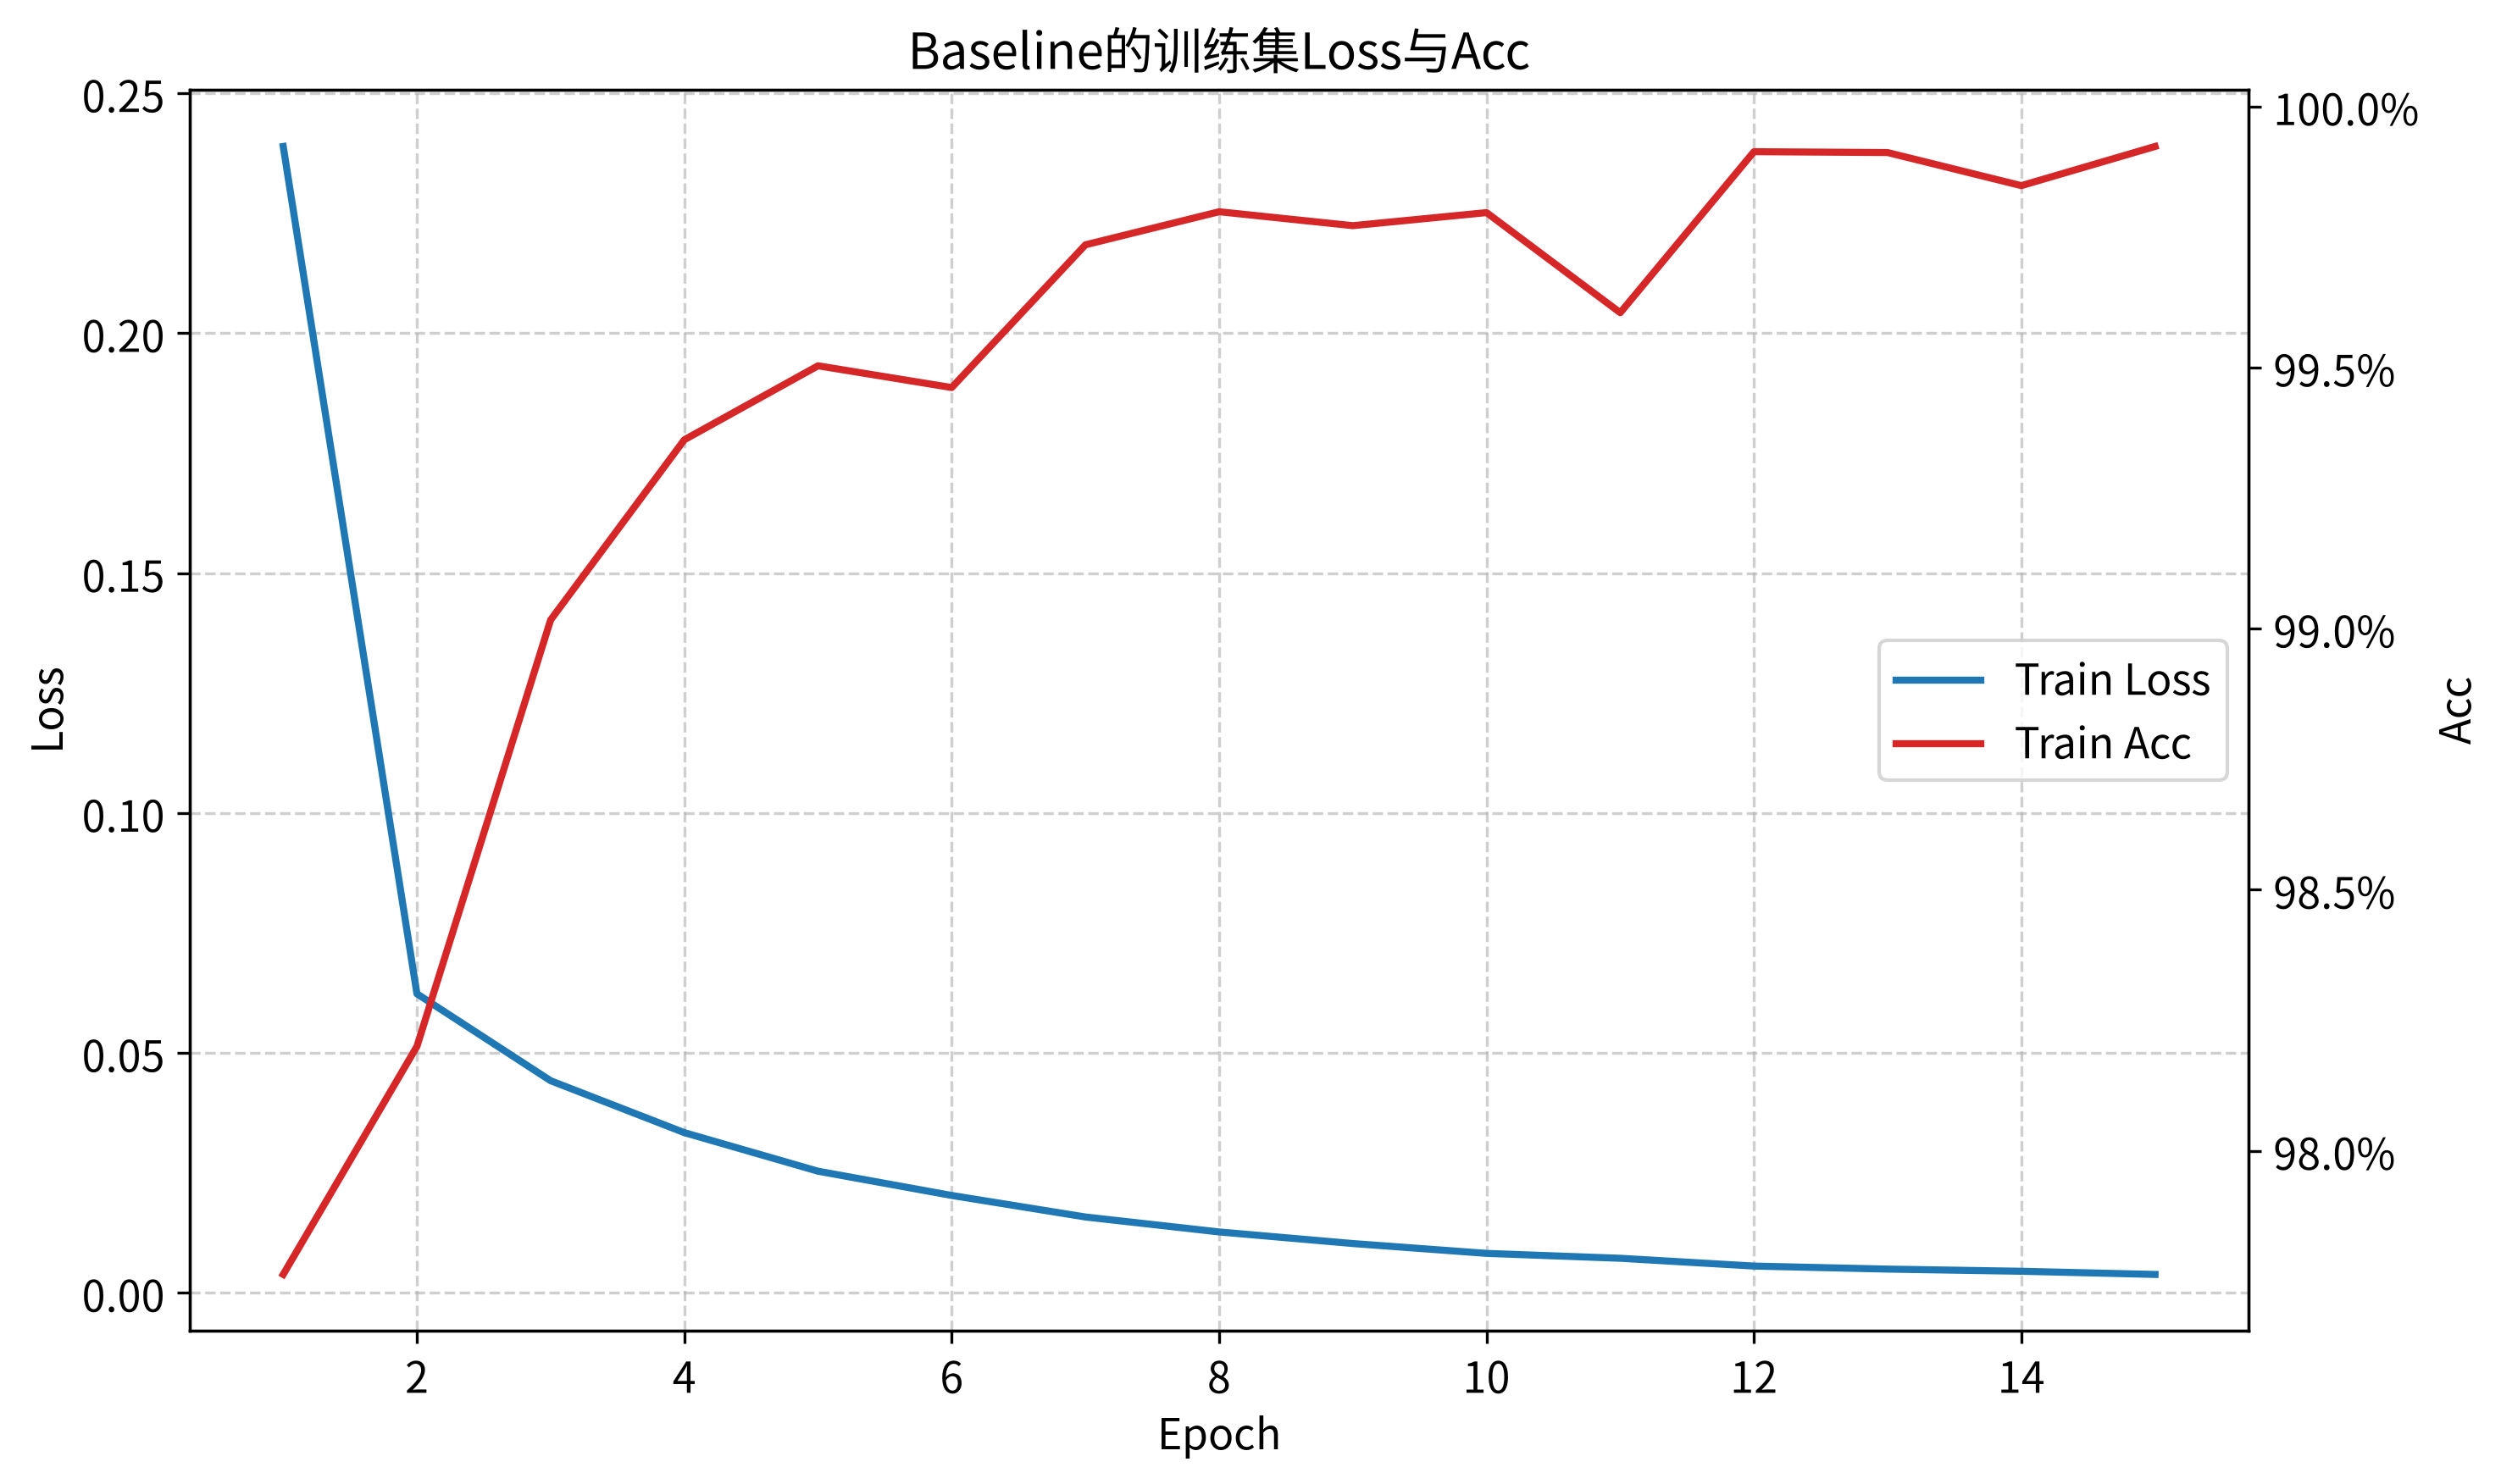

In [ ]:
# 从结果列表中提取 loss 和 acc 数据
losses = train_result_df['Loss']
accs = train_result_df['Acc']
epochs = range(1, len(losses) + 1)

# 初始化画布
fig, ax1 = plt.subplots(figsize=(10, 6)) # ax1 作为左侧主坐标轴

# 绘制左侧Loss（蓝线）
color_loss = 'tab:blue'
line1 = ax1.plot(epochs, losses, label='Train Loss', color=color_loss, linewidth=2)
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Loss', fontsize=12)
ax1.tick_params(axis='y') # 刻度线颜色与线条一致
ax1.grid(True, linestyle='--', alpha=0.6) # 加网格

# 绘制右侧Acc（红线）
ax2 = ax1.twinx()  
color_acc = 'tab:red'
line2 = ax2.plot(epochs, accs, label='Train Acc', color=color_acc, linewidth=2)
ax2.set_ylabel('Acc', fontsize=12)
ax2.tick_params(axis='y')

ax2.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0, decimals=1)) # 将Acc轴格式化为百分比

# 合并图例
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center right', fontsize=12)

# 设置标题并显示
plt.title('Baseline的训练集Loss与Acc', fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
# 在测试集上评估模型并预测
def evaluate_model(model, batch):
    model.eval() # 将模型切换到测试状态
    test_correct = 0
    test_num = 0
    test_total_loss_sum = 0.0

    test_result = []
    test_probs = []

    with torch.no_grad(): # 关闭梯度计算，节省内存
        for batch_x, batch_y in test_loader:
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)

            test_preds = model(batch_x) # 前向传播
            loss = criterion(test_preds, batch_y) # 计算单batch的平均loss
            test_total_loss_sum += loss.item() * batch_y.size(0) # 为便于最后计算总平均loss，通过乘以batch样本数，加和单batch下的loss总和
            
            predicted_classes = torch.argmax(test_preds, dim=1) # 将概率最大的标签值，作为预测结果
            test_correct += (predicted_classes == batch_y).sum().item() # 统计预测正确的样本数
            test_num += batch_y.size(0) # 统计测试集总样本数

            test_result += predicted_classes.tolist() # 追加预测结果（argmax 概率）
            test_probs += torch.softmax(test_preds, dim=1).tolist() # 追加每个数字的预测概率

    avg_test_loss = test_total_loss_sum / test_num  # 计算总平均loss
    accuracy = test_correct / test_num    # 计算Acc

    print(f"测试集loss: {avg_test_loss:.4f}")
    print(f"测试集Acc: {accuracy * 100:.2f}%  ({test_correct}/{test_num})")

    # 预测结果
    result_df = pd.DataFrame(test_result, columns=['Predict'])
    # 预测该数字为0-9的原始概率
    prob_columns = [f'Prob_{i}' for i in range(10)] 
    prob_df = pd.DataFrame(test_probs, columns=prob_columns)
    # 合并成一个df
    result_df = pd.concat([result_df, prob_df], axis=1)
    
    return result_df

In [ ]:
test_result = evaluate_model(model, batch=128)
test_result.round(4)

测试集loss: 0.0362
测试集Acc: 99.02%  (9902/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9996,3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
9997,4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
9998,5,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
